In [1]:
"""
Compare cell-specific GRNs (weighted mixtures of D=4 modules) against
CellOracle's global GRN and cluster-specific GRNs, using average per-TF
Spearman correlation as the metric.

For each cell:
  1. Build its cell-specific GRN:  A_cell = sum_d weights[cell, d] * A_dict[d]
  2. Restrict to the gene/TF intersection with the CellOracle universe
  3. For each TF column, Spearman-correlate A_cell[:, tf] vs CO_GRN[:, tf]
     across the shared gene set, then average across TFs.
  4. Do this once against the CO global GRN, once against the CO GRN of
     that cell's own Leiden cluster.

Memory strategy: we never materialize a (cells, G, T) array. We restrict
A_dict and the CO matrices to the shared gene/TF set ONCE (small matrices),
then loop over cells computing only a (Gc, Tc)-sized matrix per cell.
Per-TF Spearman is vectorized (rank + column-wise Pearson on ranks),
so there's no inner Python loop over TFs either.
"""

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
BASE = "/home/elicanter/bert_grn_out_61_masking2"
CO_BASE = "/home/elicanter/cell_oracle_run"
N_CLUSTERS = 9

# If you have >~500 cells and this is too slow, set N_SAMPLE to cap it.
# Set to None to use all cells.
N_SAMPLE = 400
RANDOM_SEED = 0

OUT_DIR = f"{BASE}/run0"

# ----------------------------------------------------------------------
# Load your method's outputs
# ----------------------------------------------------------------------
weights = np.load(f"{BASE}/run0/mix_weights.npy")      # (cells, D)
A_dict  = np.load(f"{BASE}/run0/A_dict.npy")            # (D, G, T)
A_genes = np.load(f"{BASE}/run0/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{BASE}/run0/A_tfs.npy", allow_pickle=True).astype(str)

n_cells, D = weights.shape
print(f"Loaded weights: {weights.shape}, A_dict: {A_dict.shape}")
assert A_dict.shape[0] == D

# ----------------------------------------------------------------------
# Load CellOracle global GRN
# ----------------------------------------------------------------------
co_A     = np.load(f"{CO_BASE}/cell_oracle_global_A/A_celloracle.npy")  # (G_co, T_co)
co_genes = np.load(f"{CO_BASE}/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs   = np.load(f"{CO_BASE}/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)

# ----------------------------------------------------------------------
# Load CellOracle cluster GRNs
# ----------------------------------------------------------------------
cluster_As = [
    np.load(f"{CO_BASE}/A_clusters/A_cluster_{k}.npy") for k in range(N_CLUSTERS)
]
# Assumed to share co_genes / co_tfs with the global GRN (same gene/TF universe).
for k, ca in enumerate(cluster_As):
    assert ca.shape == co_A.shape, (
        f"Cluster {k} GRN shape {ca.shape} != global GRN shape {co_A.shape}; "
        "cluster GRNs may have their own gene/TF universe -- if so, load "
        "per-cluster gene/tf files and adjust indexing below."
    )

# ----------------------------------------------------------------------
# Load cluster assignments per cell
# ----------------------------------------------------------------------
import celloracle as co
oracle = co.load_hdf5(f"{CO_BASE}/celloracle_hematopoiesis_imputed.celloracle.oracle")
clusters_raw = oracle.adata.obs["leiden"]

# ************************************************************************
# ASSUMPTION: row i of `weights`/`A_dict`-mix corresponds to
# oracle.adata.obs_names[i] / clusters_raw.iloc[i] (same order, same cells).
# If you instead have a barcode list for your method's cells, replace the
# next two lines with an explicit barcode-based alignment.
# ************************************************************************
assert len(clusters_raw) == n_cells, (
    f"Cell count mismatch: weights has {n_cells} cells, "
    f"oracle.adata has {len(clusters_raw)} cells. You need to align them "
    "explicitly (e.g. via barcodes) before proceeding."
)
cell_cluster = clusters_raw.astype(str).to_numpy()        # e.g. '0','1',...
cluster_to_idx = {str(k): k for k in range(N_CLUSTERS)}    # adjust if labels aren't '0'..'8'

# ----------------------------------------------------------------------
# Restrict everything to the shared gene/TF universe (once, not per cell)
# ----------------------------------------------------------------------
common_genes = np.intersect1d(A_genes, co_genes)
common_tfs   = np.intersect1d(A_tfs, co_tfs)
print(f"Shared genes: {len(common_genes)} / TFs: {len(common_tfs)}")

assert len(common_genes) > 1 and len(common_tfs) > 0, "Insufficient overlap to compute correlations."

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx   = pd.Index(A_tfs).get_indexer(common_tfs)
co_gene_idx = pd.Index(co_genes).get_indexer(common_genes)
co_tf_idx   = pd.Index(co_tfs).get_indexer(common_tfs)

# Restrict the D module GRNs to (D, Gc, Tc) -- small, cheap
A_dict_common = A_dict[:, a_gene_idx, :][:, :, a_tf_idx]   # (D, Gc, Tc)
Gc, Tc = A_dict_common.shape[1], A_dict_common.shape[2]
A_dict_flat = A_dict_common.reshape(D, Gc * Tc)             # (D, Gc*Tc)

co_global_common = co_A[co_gene_idx, :][:, co_tf_idx]        # (Gc, Tc)
cluster_common = [ca[co_gene_idx, :][:, co_tf_idx] for ca in cluster_As]  # 9 x (Gc, Tc)

# ----------------------------------------------------------------------
# Vectorized per-TF Spearman: rank each column, then column-wise Pearson
# ----------------------------------------------------------------------
def colwise_spearman_mean(X, Y):
    """X, Y: (Gc, Tc) matrices. Returns mean Spearman corr across columns,
    ignoring columns where either side is constant (NaN correlation)."""
    rx = rankdata(X, axis=0)
    ry = rankdata(Y, axis=0)
    rx = rx - rx.mean(axis=0, keepdims=True)
    ry = ry - ry.mean(axis=0, keepdims=True)
    num = (rx * ry).sum(axis=0)
    denom = np.sqrt((rx ** 2).sum(axis=0) * (ry ** 2).sum(axis=0))
    with np.errstate(invalid="ignore", divide="ignore"):
        corr = num / denom
    return np.nanmean(corr)

# ----------------------------------------------------------------------
# Choose cells (sample if requested)
# ----------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_SEED)
if N_SAMPLE is not None and N_SAMPLE < n_cells:
    cell_indices = rng.choice(n_cells, size=N_SAMPLE, replace=False)
    cell_indices.sort()
    print(f"Sampling {N_SAMPLE} of {n_cells} cells.")
else:
    cell_indices = np.arange(n_cells)
    print(f"Using all {n_cells} cells.")

# ----------------------------------------------------------------------
# Main loop: per cell, build its GRN (restricted), score vs global & cluster
# ----------------------------------------------------------------------
global_scores = np.full(len(cell_indices), np.nan)
cluster_scores = np.full(len(cell_indices), np.nan)
skipped = []

for out_i, i in enumerate(cell_indices):
    w = weights[i]                                  # (D,)
    A_cell = (w @ A_dict_flat).reshape(Gc, Tc)       # (Gc, Tc), cheap

    global_scores[out_i] = colwise_spearman_mean(A_cell, co_global_common)

    clab = cell_cluster[i]
    if clab not in cluster_to_idx:
        skipped.append(i)
        continue
    k = cluster_to_idx[clab]
    cluster_scores[out_i] = colwise_spearman_mean(A_cell, cluster_common[k])

    if (out_i + 1) % 100 == 0:
        print(f"  processed {out_i + 1}/{len(cell_indices)} cells")

if skipped:
    print(f"Warning: {len(skipped)} cells had an unmapped cluster label and were skipped for the cluster comparison.")

# ----------------------------------------------------------------------
# Summarize
# ----------------------------------------------------------------------
mean_global = np.nanmean(global_scores)
mean_cluster = np.nanmean(cluster_scores)

print(f"\nMean per-cell avg per-TF Spearman vs CO GLOBAL : {mean_global:.4f}  (n={np.sum(~np.isnan(global_scores))})")
print(f"Mean per-cell avg per-TF Spearman vs CO CLUSTER: {mean_cluster:.4f}  (n={np.sum(~np.isnan(cluster_scores))})")

#np.save(f"{OUT_DIR}/per_cell_spearman_vs_global.npy", global_scores)
#np.save(f"{OUT_DIR}/per_cell_spearman_vs_cluster.npy", cluster_scores)
#np.save(f"{OUT_DIR}/sampled_cell_indices.npy", cell_indices)

#print(f"\nSaved per-cell arrays and sampled indices to {OUT_DIR}")

Loaded weights: (1035, 4), A_dict: (4, 11483, 277)


ImportError: libtiff.so.5: cannot open shared object file: No such file or directory

In [6]:
"""
Compare cell-specific GRNs (weighted mixtures of D=4 modules) against
CellOracle's global GRN and cluster-specific GRNs, using average per-TF
Spearman correlation as the metric.

For each cell:
  1. Build its cell-specific GRN:  A_cell = sum_d weights[cell, d] * A_dict[d]
  2. Restrict to the gene/TF intersection with the CellOracle universe
  3. For each TF column, Spearman-correlate A_cell[:, tf] vs CO_GRN[:, tf]
     across the shared gene set, then average across TFs.
  4. Do this once against the CO global GRN, once against the CO GRN of
     that cell's own Leiden cluster.

Memory strategy: we never materialize a (cells, G, T) array. We restrict
A_dict and the CO matrices to the shared gene/TF set ONCE (small matrices),
then loop over cells computing only a (Gc, Tc)-sized matrix per cell.
Per-TF Spearman is vectorized (rank + column-wise Pearson on ranks),
so there's no inner Python loop over TFs either.
"""

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
BASE = "/home/elicanter/bert_grn_out_61_masking2"
CO_BASE = "/home/elicanter/cell_oracle_run"
N_CLUSTERS = 9

# If you have >~500 cells and this is too slow, set N_SAMPLE to cap it.
# Set to None to use all cells.
N_SAMPLE = None
RANDOM_SEED = 0

OUT_DIR = f"{BASE}/run0"

# ----------------------------------------------------------------------
# Load your method's outputs
# ----------------------------------------------------------------------
weights = np.load(f"{BASE}/run0/mix_weights.npy")      # (cells, D)
A_dict  = np.load(f"{BASE}/run0/A_dict.npy")            # (D, G, T)
A_genes = np.load(f"{BASE}/run0/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{BASE}/run0/A_tfs.npy", allow_pickle=True).astype(str)

n_cells, D = weights.shape
print(f"Loaded weights: {weights.shape}, A_dict: {A_dict.shape}")
assert A_dict.shape[0] == D

# ----------------------------------------------------------------------
# Load CellOracle global GRN
# ----------------------------------------------------------------------
co_A     = np.load(f"{CO_BASE}/cell_oracle_global_A/A_celloracle.npy")  # (G_co, T_co)
co_genes = np.load(f"{CO_BASE}/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs   = np.load(f"{CO_BASE}/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)

# ----------------------------------------------------------------------
# Load CellOracle cluster GRNs
# ----------------------------------------------------------------------
cluster_As = [
    np.load(f"{CO_BASE}/A_clusters/A_cluster_{k}.npy") for k in range(N_CLUSTERS)
]

# ----------------------------------------------------------------------
# Normalize orientation to (genes, TFs). CellOracle matrices are sometimes
# stored as (TFs, genes) instead -- detect and transpose if needed.
# ----------------------------------------------------------------------
def to_genes_by_tfs(mat, n_genes, n_tfs, name):
    if mat.shape == (n_genes, n_tfs):
        return mat
    elif mat.shape == (n_tfs, n_genes):
        print(f"  {name}: detected (TFs, genes) orientation {mat.shape}, transposing.")
        return mat.T
    else:
        raise ValueError(
            f"{name} has shape {mat.shape}, which matches neither "
            f"(genes={n_genes}, TFs={n_tfs}) nor (TFs={n_tfs}, genes={n_genes})."
        )

n_co_genes, n_co_tfs = len(co_genes), len(co_tfs)
co_A = to_genes_by_tfs(co_A, n_co_genes, n_co_tfs, "co_A (global)")
cluster_As = [
    to_genes_by_tfs(ca, n_co_genes, n_co_tfs, f"cluster_As[{k}]")
    for k, ca in enumerate(cluster_As)
]

for k, ca in enumerate(cluster_As):
    assert ca.shape == co_A.shape, (
        f"Cluster {k} GRN shape {ca.shape} != global GRN shape {co_A.shape}; "
        "cluster GRNs may have their own gene/TF universe -- if so, load "
        "per-cluster gene/tf files and adjust indexing below."
    )

# ----------------------------------------------------------------------
# Load cluster assignments per cell
# ----------------------------------------------------------------------

clusters_raw = np.load("/home/elicanter/cell_oracle_run/clusters_raw.npy", allow_pickle=True)

# ************************************************************************
# ASSUMPTION: row i of `weights`/`A_dict`-mix corresponds to
# oracle.adata.obs_names[i] / clusters_raw.iloc[i] (same order, same cells).
# If you instead have a barcode list for your method's cells, replace the
# next two lines with an explicit barcode-based alignment.
# ************************************************************************
assert len(clusters_raw) == n_cells, (
    f"Cell count mismatch: weights has {n_cells} cells, "
    f"oracle.adata has {len(clusters_raw)} cells. You need to align them "
    "explicitly (e.g. via barcodes) before proceeding."
)
cell_cluster = clusters_raw.astype(str)      # e.g. '0','1',...
cluster_to_idx = {str(k): k for k in range(N_CLUSTERS)}    # adjust if labels aren't '0'..'8'

# ----------------------------------------------------------------------
# Restrict everything to the shared gene/TF universe (once, not per cell)
# ----------------------------------------------------------------------
common_genes = np.intersect1d(A_genes, co_genes)
common_tfs   = np.intersect1d(A_tfs, co_tfs)
print(f"Shared genes: {len(common_genes)} / TFs: {len(common_tfs)}")

assert len(common_genes) > 1 and len(common_tfs) > 0, "Insufficient overlap to compute correlations."

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx   = pd.Index(A_tfs).get_indexer(common_tfs)
co_gene_idx = pd.Index(co_genes).get_indexer(common_genes)
co_tf_idx   = pd.Index(co_tfs).get_indexer(common_tfs)

# Restrict the D module GRNs to (D, Gc, Tc) -- small, cheap
A_dict_common = A_dict[:, a_gene_idx, :][:, :, a_tf_idx]   # (D, Gc, Tc)
Gc, Tc = A_dict_common.shape[1], A_dict_common.shape[2]
A_dict_flat = A_dict_common.reshape(D, Gc * Tc)             # (D, Gc*Tc)

co_global_common = np.abs(co_A[co_gene_idx, :][:, co_tf_idx])        # (Gc, Tc)
cluster_common = np.abs([ca[co_gene_idx, :][:, co_tf_idx] for ca in cluster_As])  # 9 x (Gc, Tc)

# ----------------------------------------------------------------------
# Vectorized per-TF Spearman: rank each column, then column-wise Pearson
# ----------------------------------------------------------------------
def colwise_spearman_mean(X, Y):
    """X, Y: (Gc, Tc) matrices. Returns mean Spearman corr across columns,
    ignoring columns where either side is constant (NaN correlation)."""
    rx = rankdata(X, axis=0)
    ry = rankdata(Y, axis=0)
    rx = rx - rx.mean(axis=0, keepdims=True)
    ry = ry - ry.mean(axis=0, keepdims=True)
    num = (rx * ry).sum(axis=0)
    denom = np.sqrt((rx ** 2).sum(axis=0) * (ry ** 2).sum(axis=0))
    with np.errstate(invalid="ignore", divide="ignore"):
        corr = num / denom
    return np.nanmean(corr)

# ----------------------------------------------------------------------
# Choose cells (sample if requested)
# ----------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_SEED)
if N_SAMPLE is not None and N_SAMPLE < n_cells:
    cell_indices = rng.choice(n_cells, size=N_SAMPLE, replace=False)
    cell_indices.sort()
    print(f"Sampling {N_SAMPLE} of {n_cells} cells.")
else:
    cell_indices = np.arange(n_cells)
    print(f"Using all {n_cells} cells.")

# ----------------------------------------------------------------------
# Main loop: per cell, build its GRN (restricted), score vs global & cluster
# ----------------------------------------------------------------------
global_scores = np.full(len(cell_indices), np.nan)
cluster_scores = np.full(len(cell_indices), np.nan)
wrong_cluster_scores = np.full(len(cell_indices), np.nan)
skipped = []

for out_i, i in enumerate(cell_indices):
    w = weights[i]                                  # (D,)
    A_cell = np.abs((w @ A_dict_flat).reshape(Gc, Tc))       # (Gc, Tc), cheap

    global_scores[out_i] = colwise_spearman_mean(A_cell, co_global_common)

    clab = cell_cluster[i]
    if clab not in cluster_to_idx:
        skipped.append(i)
        continue
    k = cluster_to_idx[clab]
    cluster_scores[out_i] = colwise_spearman_mean(A_cell, cluster_common[k])

    wrong_cluster_scores[out_i] = colwise_spearman_mean(A_cell, cluster_common[np.random.choice(np.delete(np.arange(9), k))])

    if (out_i + 1) % 100 == 0:
        print(f"  processed {out_i + 1}/{len(cell_indices)} cells")

if skipped:
    print(f"Warning: {len(skipped)} cells had an unmapped cluster label and were skipped for the cluster comparison.")

# ----------------------------------------------------------------------
# Summarize
# ----------------------------------------------------------------------
mean_global = np.nanmean(global_scores)
mean_cluster = np.nanmean(cluster_scores)
mean_wrong_cluster = np.nanmean(wrong_cluster_scores)

print(f"\nMean per-cell avg per-TF Spearman vs CO GLOBAL : {mean_global:.4f}  (n={np.sum(~np.isnan(global_scores))})")
print(f"Mean per-cell avg per-TF Spearman vs CO CLUSTER: {mean_cluster:.4f}  (n={np.sum(~np.isnan(cluster_scores))})")
print(f"Mean per-cell avg per-TF Spearman vs wrong CO CLUSTER: {mean_wrong_cluster:.4f}  (n={np.sum(~np.isnan(cluster_scores))})")


#np.save(f"{OUT_DIR}/per_cell_spearman_vs_global.npy", global_scores)
#np.save(f"{OUT_DIR}/per_cell_spearman_vs_cluster.npy", cluster_scores)
#np.save(f"{OUT_DIR}/sampled_cell_indices.npy", cell_indices)

#print(f"\nSaved per-cell arrays and sampled indices to {OUT_DIR}")

Loaded weights: (1035, 4), A_dict: (4, 11483, 277)
  co_A (global): detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[0]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[1]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[2]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[3]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[4]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[5]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[6]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[7]: detected (TFs, genes) orientation (277, 2995), transposing.
  cluster_As[8]: detected (TFs, genes) orientation (277, 2995), transposing.
Shared genes: 2995 / TFs: 277
Using all 1035 cells.


KeyboardInterrupt: 

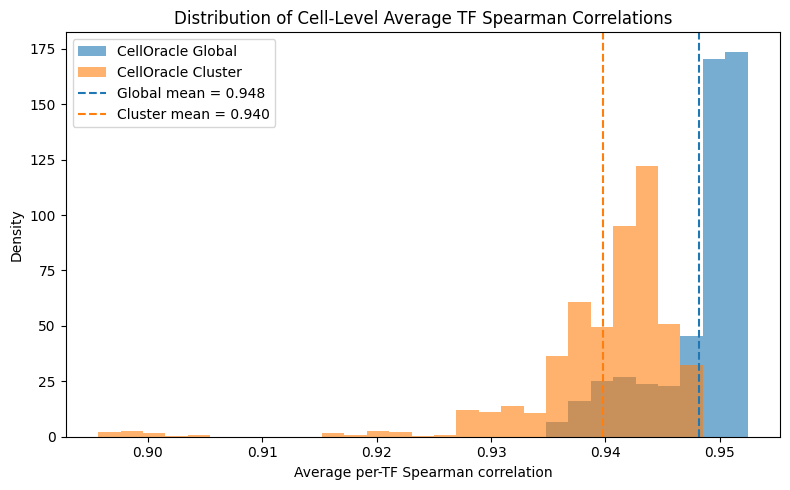

In [16]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


# Remove NaNs
global_valid = global_scores[~np.isnan(global_scores)]
cluster_valid = cluster_scores[~np.isnan(cluster_scores)]

plt.figure(figsize=(8, 5))

bins = np.linspace(
    min(global_valid.min(), cluster_valid.min()),
    max(global_valid.max(), cluster_valid.max()),
    30,
)

plt.hist(
    global_valid,
    bins=bins,
    alpha=0.6,
    label="CellOracle Global",
    density=True,
)

plt.hist(
    cluster_valid,
    bins=bins,
    alpha=0.6,
    label="CellOracle Cluster",
    density=True,
)

plt.axvline(global_valid.mean(), color="C0", linestyle="--",
            label=f"Global mean = {global_valid.mean():.3f}")
plt.axvline(cluster_valid.mean(), color="C1", linestyle="--",
            label=f"Cluster mean = {cluster_valid.mean():.3f}")

plt.xlabel("Average per-TF Spearman correlation")
plt.ylabel("Density")
plt.title("Distribution of Cell-Level Average TF Spearman Correlations")
plt.legend()
plt.tight_layout()
plt.show()

#print(f"Global:  mean={global_valid.mean():.4f}, std={global_valid.std():.4f}, n={len(global_valid)}")
#print(f"Cluster: mean={cluster_valid.mean():.4f}, std={cluster_valid.std():.4f}, n={len(cluster_valid)}")

/tmp/ipykernel_4002/2515638642.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


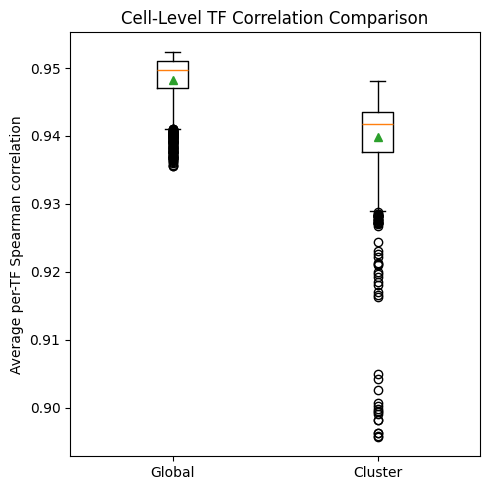

In [13]:
plt.figure(figsize=(5, 5))

plt.boxplot(
    [global_valid, cluster_valid],
    labels=["Global", "Cluster"],
    showmeans=True,
)

plt.ylabel("Average per-TF Spearman correlation")
plt.title("Cell-Level TF Correlation Comparison")
plt.tight_layout()
plt.show()

In [17]:
# ----------------------------------------------------------------------
# Population-averaged GRN: combine modules using the mean mixing weights
# across all cells, then compare to the CO global GRN
# ----------------------------------------------------------------------
mean_weights = weights.mean(axis=0)                       # (D,)
A_pop = (mean_weights @ A_dict_flat).reshape(Gc, Tc)       # (Gc, Tc)

pop_vs_global_spearman = colwise_spearman_mean(np.abs(A_pop), np.abs(co_global_common))

print(f"\nAverage per-TF Spearman, population-averaged GRN vs CO GLOBAL: {pop_vs_global_spearman:.4f}")


Average per-TF Spearman, population-averaged GRN vs CO GLOBAL: 0.9516


In [11]:
cluster_scores2 = []
for k in range(9):
    cluster_scores2.append(colwise_spearman_mean(np.abs(A_pop), np.abs(cluster_common[k])))

np.nanmean(cluster_scores2)

np.float64(0.9373339324546084)

In [18]:
cluster_scores3 = []
for k in range(8):
    for j in range(k+1, 9):
        cluster_scores3.append(colwise_spearman_mean(np.abs(cluster_common[k]), np.abs(cluster_common[j])))

np.nanmean(cluster_scores3)

np.float64(0.9311107642013757)

In [19]:
import numpy as np

n = len(cluster_common)
sim = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            sim[i, j] = 1.0
        else:
            sim[i, j] = colwise_spearman_mean(
                np.abs(cluster_common[i]),
                np.abs(cluster_common[j])
            )

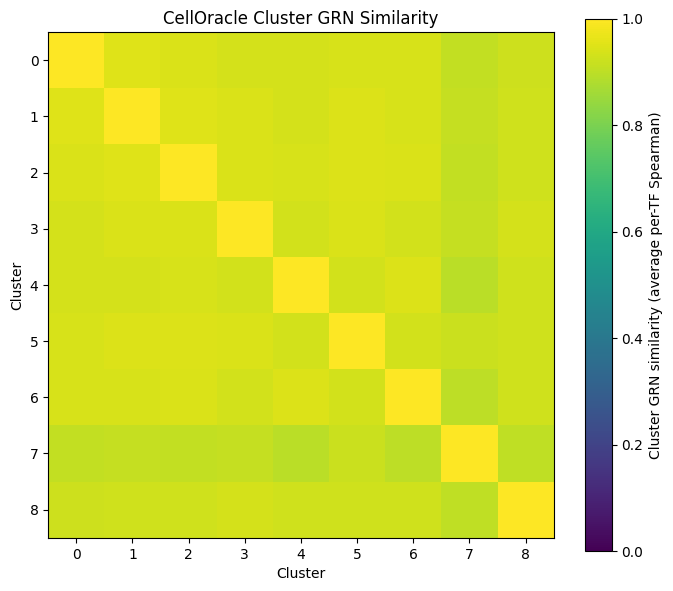

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

im = plt.imshow(sim, vmin=0, vmax=1, cmap="viridis")
plt.colorbar(im, label="Cluster GRN similarity (average per-TF Spearman)")

plt.title("CellOracle Cluster GRN Similarity")
plt.xlabel("Cluster")
plt.ylabel("Cluster")

plt.xticks(range(n))
plt.yticks(range(n))

plt.tight_layout()
plt.show()

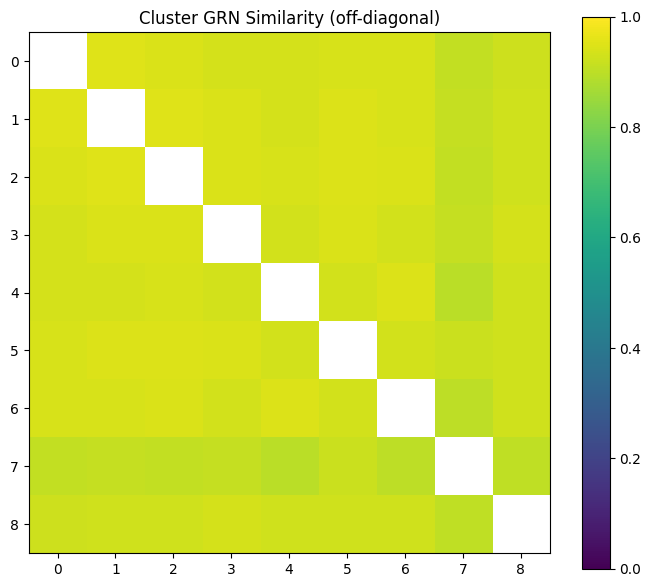

In [21]:
plt.figure(figsize=(7, 6))

mask = np.eye(n, dtype=bool)
plot_mat = sim.copy()
plot_mat[mask] = np.nan

im = plt.imshow(plot_mat, vmin=0, vmax=1, cmap="viridis")
plt.colorbar(im)

plt.title("Cluster GRN Similarity (off-diagonal)")
plt.xticks(range(n))
plt.yticks(range(n))

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# ----------------------------------------------------------------------
# STORAGE
# ----------------------------------------------------------------------
n_clusters = len(cluster_common)

top1_correct = 0
topk_correct = 0

K = 1   # <<< choose top-k here

all_ranks = []

# ----------------------------------------------------------------------
# MAIN LOOP
# ----------------------------------------------------------------------
for idx, i in enumerate(cell_indices):

    # build cell GRN
    w = weights[i]
    A_cell = np.abs((w @ A_dict_flat).reshape(Gc, Tc))

    # score vs ALL clusters
    cluster_scores_cell = np.zeros(n_clusters)

    for k in range(n_clusters):
        cluster_scores_cell[k] = colwise_spearman_mean(
            A_cell,
            cluster_common[k]
        )

    # rank clusters (higher = better match)
    ranked_clusters = np.argsort(-cluster_scores_cell)  # descending

    true_cluster = cluster_to_idx[cell_cluster[i]]

    # top-1 accuracy
    if ranked_clusters[0] == true_cluster:
        top1_correct += 1

    # top-k accuracy
    if true_cluster in ranked_clusters[:K]:
        topk_correct += 1

    all_ranks.append(np.where(ranked_clusters == true_cluster)[0][0])

    if (idx + 1) % 100 == 0:
        print(f"Processed {idx+1}/{len(cell_indices)}")

# ----------------------------------------------------------------------
# RESULTS
# ----------------------------------------------------------------------
n_eval = len(cell_indices)

top1_acc = top1_correct / n_eval
topk_acc = topk_correct / n_eval
mean_rank = np.mean(all_ranks)

print("\n==============================")
print("CLUSTER PREDICTION RESULTS")
print("==============================")
print(f"Top-1 accuracy : {top1_acc:.4f}")
print(f"Top-{K} accuracy: {topk_acc:.4f}")
print(f"Mean true-cluster rank: {mean_rank:.2f} (1 = perfect)")

KeyboardInterrupt: 

In [25]:
import numpy as np

# ----------------------------------------------------------------------
# SETTINGS
# ----------------------------------------------------------------------
FRACTION = 0.2        # <<< fraction of cells to sample (e.g. 20%)
N_REPEATS = 1         # bootstrap repeats for stability
K = 3              # top-k accuracy

rng = np.random.default_rng(0)

n_clusters = len(cluster_common)

top1_scores = []
topk_scores = []

# ----------------------------------------------------------------------
# BOOTSTRAP LOOP
# ----------------------------------------------------------------------
for rep in range(N_REPEATS):

    # ---- sample cells ----
    n_sample = int(FRACTION * len(cell_indices))
    sampled_cells = rng.choice(cell_indices, size=n_sample, replace=False)

    top1_correct = 0
    topk_correct = 0

    for i in sampled_cells:

        # build cell GRN
        w = weights[i]
        A_cell = np.abs((w @ A_dict_flat).reshape(Gc, Tc))

        # score against all clusters
        scores = np.zeros(n_clusters)

        for k in range(n_clusters):
            scores[k] = colwise_spearman_mean(A_cell, cluster_common[k])

        ranked = np.argsort(-scores)

        true_k = cluster_to_idx[cell_cluster[i]]

        # top-1
        if ranked[0] == true_k:
            top1_correct += 1

        # top-k
        if true_k in ranked[:K]:
            topk_correct += 1

    top1_acc = top1_correct / n_sample
    topk_acc = topk_correct / n_sample

    top1_scores.append(top1_acc)
    topk_scores.append(topk_acc)

    print(f"Repeat {rep+1}: Top1={top1_acc:.4f}, Top{K}={topk_acc:.4f}")

# ----------------------------------------------------------------------
# SUMMARY
# ----------------------------------------------------------------------
print("\n========================")
print("SAMPLED EVALUATION")
print("========================")

print(f"Fraction sampled: {FRACTION}")
print(f"Top-1 accuracy : {np.mean(top1_scores):.4f} ± {np.std(top1_scores):.4f}")
print(f"Top-{K} accuracy: {np.mean(topk_scores):.4f} ± {np.std(topk_scores):.4f}")

Repeat 1: Top1=0.2126, Top3=0.3865

SAMPLED EVALUATION
Fraction sampled: 0.2
Top-1 accuracy : 0.2126 ± 0.0000
Top-3 accuracy: 0.3865 ± 0.0000
